Hogares NL: 3608 | Zonas NL: 37


C:\Users\hugod\AppData\Local\Temp\ipykernel_6244\186961654.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_hog['ubica_geo_str'] = df_hog['ubica_geo'].astype(str).str.zfill(5)


,anio,indice_demanda,indice_oferta,brecha
0,2026,100.000000,0.000032,99.999968
1,2027,104.500000,0.000034,104.499966
2,2028,109.202500,0.000037,109.202463
3,2029,114.116612,0.000039,114.116573
4,2030,119.251860,0.000042,119.251818


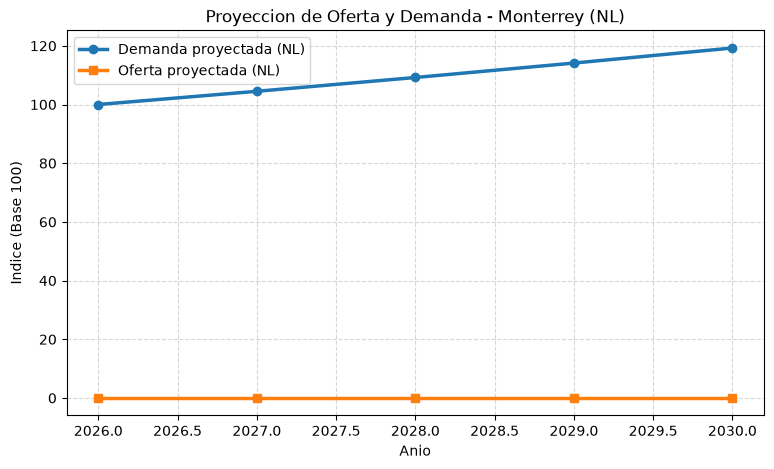

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_hog = pd.read_csv('../data/processed/datos_modelo_final.csv')
df_esp = pd.read_csv('../data/processed/matriz_espacial_fase2.csv')

df_hog['ubica_geo_str'] = df_hog['ubica_geo'].astype(str).str.zfill(5)
df_esp['ubica_geo_str'] = df_esp['ubica_geo'].astype(str).str.zfill(5)

hog_nl = df_hog[(df_hog['entidad'] == 19) | (df_hog['ubica_geo_str'].str.startswith('19'))].copy()
esp_nl = df_esp[df_esp['ubica_geo_str'].str.startswith('19')].copy()

print('Hogares NL:', len(hog_nl), '| Zonas NL:', len(esp_nl))

if len(esp_nl) > 0 and 'ingreso_total_zona' in esp_nl.columns:
    demanda_base = float(esp_nl['ingreso_total_zona'].sum())
else:
    factor_col = hog_nl['factor'] if 'factor' in hog_nl.columns else pd.Series(1, index=hog_nl.index)
    demanda_base = float((hog_nl['ingreso_total'] * factor_col).sum())

oferta_base = float((esp_nl['total_competidores'].fillna(0) + esp_nl['masa_negocios_b2b'].fillna(0)).sum()) if len(esp_nl) > 0 else 1.0

idx_demanda_0 = 100.0
idx_oferta_0 = (oferta_base / demanda_base) * 100.0 if demanda_base > 0 else 50.0

anios = np.arange(2026, 2031)
t = anios - anios[0]
demanda_proy = idx_demanda_0 * ((1 + 0.045) ** t)
oferta_proy = idx_oferta_0 * ((1 + 0.070) ** t)

df_proy_nl = pd.DataFrame({'anio': anios, 'indice_demanda': demanda_proy, 'indice_oferta': oferta_proy, 'brecha': demanda_proy - oferta_proy})
display(df_proy_nl)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(anios, demanda_proy, marker='o', linewidth=2.5, label='Demanda proyectada (NL)')
ax.plot(anios, oferta_proy, marker='s', linewidth=2.5, label='Oferta proyectada (NL)')
ax.set_title('Proyeccion de Oferta y Demanda - Monterrey (NL)')
ax.set_xlabel('Anio')
ax.set_ylabel('Indice (Base 100)')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.show()
